# Comparable-company matching from website text: Paylocity (PCTY)

**Goal.** Treat Paylocity as if it were a private target and find its closest comparables among the
560-company universe, using only the scraped website descriptions (company names are already masked as `[COMPANY]`).

**Pipeline**
1. Load the metadata CSV + full scraped text, and set aside companies with unusable text (with a reason).
2. Clean the text: drop boilerplate (cookies, legal, investor-relations notices) and sentences repeated across sites.
3. Represent each company three ways: **TF-IDF** (transparent baseline), **LSA** (semantic compression of TF-IDF),
   and optional **sentence embeddings** (runs if `sentence-transformers` is installed).
4. Score cosine similarity to the target; build an **ensemble** (mean of z-scored similarities).
5. Validate: (a) a hand-labeled peer set fixed *before* looking at results, scored with NDCG / recall@k;
   (b) a universe-wide check of how often neighbors share a SIC4 code vs. a random baseline;
   (c) agreement between methods and a text-length bias check.
6. Output: a ranked comps table with "why similar" terms, a 2-D map, and a reusable `find_comps(ticker)`.

SIC codes are deliberately **not** used in the score. They serve only as a separate column and a weak
validation signal (SIC 7370 groups a game studio with Paycom).

## 0. Setup

In [31]:
import os, re, json, collections, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from sklearn.manifold import TSNE

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 300)
pd.set_option("display.width", 200)
RNG = 0

In [32]:
# ---- CONFIG -----------------------------------------------------------------
# Put this notebook in the folder that holds descriptions.csv and text/
# (e.g. .../Qual2Cast/descriptions_output_riya/), or point BASE_DIR there.
BASE_DIR  = Path("/Users/riya/Columbia/Qual2Cast/descriptions_output_riya")
CSV_PATH  = "../descriptions_output_riya/descriptions.csv"
TEXT_DIR  = BASE_DIR            # text_file column already starts with "text/..."
OUT_DIR   = BASE_DIR / "comps_output"
OUT_DIR.mkdir(exist_ok=True)

TARGET    = "PCTY"              # ticker of the "private" target
TOP_K     = 25                  # size of the comps list we report
MIN_WORDS = 100                 # minimum cleaned words to be matchable

USE_EMBEDDINGS  = True          # silently skipped if sentence-transformers isn't installed
EMBED_MODEL     = "sentence-transformers/all-mpnet-base-v2"   # or "BAAI/bge-large-en-v1.5"
EMBED_CACHE     = OUT_DIR / "embeddings_mpnet.npy"

# Hand-labeled peers for the target, fixed from domain knowledge BEFORE looking at any output.
# 2 = direct competitor (HCM/payroll software), 1 = HR-adjacent (PEO, benefits admin,
# screening, workforce SaaS, talent services, employment data).  Review/edit with the team.
PEER_LABELS = {
    "PAYC": 2, "ADP": 2, "ASUR": 2,
    "BBSI": 1, "ALIT": 1, "INTU": 1, "FA": 1, "HSTM": 1, "KFY": 1, "HQI": 1, "EFX": 1,
}

## 1. Load data and set aside unusable rows

In [33]:
meta = pd.read_csv(CSV_PATH)

def read_text(rel):
    if not isinstance(rel, str):
        return ""
    p = TEXT_DIR / rel
    return p.read_text(encoding="utf-8", errors="ignore") if p.exists() else ""

meta["raw_text"] = meta["text_file"].map(read_text)
meta["raw_words"] = meta["raw_text"].str.split().str.len()
print(f"{len(meta)} companies | text files found: {(meta.raw_words > 0).sum()}")
meta["status"].str.split(":").str[0].value_counts()

560 companies | text files found: 521


status
ok                   489
thin_content          35
robots_disallowed     27
http_403               4
error                  3
http_404               1
blocked_bot_check      1
Name: count, dtype: int64

## 2. Clean the text

Website copy is mostly marketing, with a lot of noise. We split it into sentences and drop:
- **boilerplate patterns**: cookie/privacy notices, legal footers, calls to action, and investor-relations
  items such as earnings dates. Earnings language also risks leaking "public company" signals, which matters
  because we are treating the target as private;
- **cross-site duplicates**: any sentence that appears on 3 or more different companies' sites
  (cookie-banner vendors, shared templates).

In [34]:
SENT_SPLIT = re.compile(r"(?<=[.!?])\s+|\s*\|\s*|\s{2,}")
BOILERPLATE = re.compile(
    r"cookie|privacy|javascript|browser|opens in a new tab|all rights reserved|copyright|©|"
    r"terms of (use|service)|subscribe|newsletter|sign up|log ?in|click (here|on)|learn more|read more|"
    r"contact us|earnings|quarter|fiscal|webcast|conference call|investor|press release|stock|nyse|nasdaq|"
    r"shareholder|personalized web experience|default settings|category headings",
    re.I,
)

def to_sentences(text):
    text = text.replace("[COMPANY]", " ")
    return [s.strip() for s in SENT_SPLIT.split(text) if len(s.split()) >= 4]

meta["sents"] = meta["raw_text"].map(to_sentences)
sent_doc_freq = collections.Counter(s.lower() for ss in meta["sents"] for s in set(ss))

def clean_sentences(ss):
    return [s for s in ss if not BOILERPLATE.search(s) and sent_doc_freq[s.lower()] < 3]

meta["clean_sents"] = meta["sents"].map(clean_sentences)
meta["clean_text"]  = meta["clean_sents"].map(" ".join)
meta["clean_words"] = meta["clean_text"].str.split().str.len()

def exclusion_reason(r):
    if r.status != "ok":            return f"scrape status: {r.status.split(':')[0]}"
    if r.clean_words < MIN_WORDS:   return f"too little text after cleaning ({r.clean_words} words)"
    return None

meta["excluded_because"] = meta.apply(exclusion_reason, axis=1)
U = meta[meta.excluded_because.isna()].reset_index(drop=True)      # the matchable universe
excluded = meta[meta.excluded_because.notna()][
    ["target_ciq_ticker", "target_company_name", "excluded_because"]]
excluded.to_csv(OUT_DIR / "excluded_companies.csv", index=False)

print(f"Matchable universe: {len(U)} companies | excluded: {len(excluded)} (saved to excluded_companies.csv)")
print(f"Share of raw words removed by cleaning: {1 - meta.clean_words.sum() / meta.raw_words.sum():.1%}")
assert TARGET in set(U.target_ciq_ticker), f"{TARGET} is not in the matchable universe"
missing_peers = set(PEER_LABELS) - set(U.target_ciq_ticker)
if missing_peers: print("Labeled peers not matchable (will count as misses):", missing_peers)

Matchable universe: 487 companies | excluded: 73 (saved to excluded_companies.csv)
Share of raw words removed by cleaning: 5.9%


In [35]:
# Sanity check: what the target looks like after cleaning
t_idx = int(U.index[U.target_ciq_ticker == TARGET][0])
print(U.loc[t_idx, "target_company_name"], "|", U.loc[t_idx, "clean_words"], "clean words\n")
print(U.loc[t_idx, "clean_text"][:1500], "...")

Paylocity Holding Corporation | 980 clean words

Unify HR, Finance, & IT HR & Payroll Simplified unifies HR, Finance, and IT on one HCM platform, so you can stop piecing systems together and start moving forward together. Everything we do starts with people At , we’re more than a leading HR, payroll, and spend management technology provider—we’re a company driven by a simple truth: People matter most. we’ve been partnering with organizations to create workplaces where employees thrive, and businesses excel. Innovation powers our solutions, but it’s our relationships that set us apart. “Forward Together” is how we work with our clients to transform the way work gets done. Combining their insights with our expertise creates solutions that make HR simpler, payroll smoother, spend management smarter, and employee engagement stronger. We’re glad you’re here. Let’s create the future of work, together. We’re growing — and growing fast. Each week, we welcome new faces across our organization t

## 3. Represent each company

| Method | What it captures | Why include it |
|---|---|---|
| TF-IDF (1–2 grams) | shared distinctive vocabulary ("payroll", "hcm", "time and labor") | transparent; the "why similar" terms come from here |
| LSA (SVD, 150 dims) | groups of words that co-occur, i.e. latent topics | handles synonyms better than raw TF-IDF and costs almost nothing |
| Sentence embeddings | meaning-level similarity from a pretrained model | strongest at paraphrase; optional, runs locally |

In [36]:
EXTRA_STOP = {
    "company", "companies", "inc", "llc", "solutions", "solution", "services", "service", "new", "help",
    "helps", "world", "leading", "leader", "people", "team", "work", "today", "year", "years", "way",
    "make", "including", "provide", "provides", "providing", "us", "our", "we", "s",
    # generic marketing fluff that carries no information about what a company does
    "smarter", "stronger", "seamless", "seamlessly", "simplify", "simplified", "simple", "save", "excel",
    "strive", "best", "innovation", "innovative", "step", "need", "needs", "right", "real", "depend",
    "steer", "future", "together", "forward", "trusted", "success", "journey", "proud", "excellence",
}
tfidf = TfidfVectorizer(
    stop_words=list(ENGLISH_STOP_WORDS | EXTRA_STOP),
    ngram_range=(1, 2), min_df=2, max_df=0.4, sublinear_tf=True,
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+(?:-[a-zA-Z]+)*\b",
)
X_tfidf = tfidf.fit_transform(U["clean_text"])          # rows are L2-normalised
vocab = np.array(tfidf.get_feature_names_out())

svd = TruncatedSVD(n_components=150, random_state=RNG)
X_lsa = normalize(svd.fit_transform(X_tfidf))
print(f"TF-IDF: {X_tfidf.shape} | LSA: {X_lsa.shape}, variance kept {svd.explained_variance_ratio_.sum():.1%}")

TF-IDF: (487, 24946) | LSA: (487, 150), variance kept 42.6%


In [37]:
def embed_universe(texts, model_name, cache_path, chunk_words=200):
    """Mean-pooled, L2-normalised sentence embeddings over ~200-word chunks (cached to disk)."""
    if cache_path.exists():
        E = np.load(cache_path)
        if E.shape[0] == len(texts):
            return E
    from sentence_transformers import SentenceTransformer
    model = SentenceTransformer(model_name)
    out = []
    for t in texts:
        w = t.split()
        chunks = [" ".join(w[i:i + chunk_words]) for i in range(0, len(w), chunk_words)] or [""]
        v = model.encode(chunks, normalize_embeddings=True).mean(axis=0)
        out.append(v / np.linalg.norm(v))
    E = np.vstack(out)
    np.save(cache_path, E)
    return E

X_emb = None
if USE_EMBEDDINGS:
    try:
        X_emb = embed_universe(U["clean_text"].tolist(), EMBED_MODEL, EMBED_CACHE)
        print("Embeddings:", X_emb.shape)
    except ImportError:
        print("sentence-transformers not installed; skipping embeddings "
              "(pip install sentence-transformers to enable). TF-IDF + LSA only.")

Embeddings: (487, 768)


## 4. Similarity and ensemble ranking

All three representations are L2-normalised, so cosine similarity is just a dot product. Similarity
scales differ across methods (TF-IDF scores are small, embedding scores are large), so each method's
scores are **z-scored across the universe** before averaging into the ensemble.

In [38]:
REPS = {"tfidf": X_tfidf, "lsa": X_lsa}
if X_emb is not None:
    REPS["embed"] = X_emb

def sim_to(idx, M):
    s = M @ M[idx].T
    return np.asarray(s.todense()).ravel() if hasattr(s, "todense") else np.asarray(s).ravel()

def zscore(s, idx):
    mask = np.arange(len(s)) != idx                 # exclude self from the stats
    return (s - s[mask].mean()) / s[mask].std()

def score_all(idx):
    S = pd.DataFrame({name: sim_to(idx, M) for name, M in REPS.items()})
    S["ensemble"] = np.mean([zscore(S[c].values, idx) for c in REPS], axis=0)
    return S

def shared_terms(i, j, n=6):
    """Terms contributing most to TF-IDF cosine(i, j): the 'why similar' column."""
    contrib = X_tfidf[i].multiply(X_tfidf[j]).toarray().ravel()
    top = contrib.argsort()[::-1][:n]
    return ", ".join(vocab[k] for k in top if contrib[k] > 0)

def find_comps(ticker, k=TOP_K, method="ensemble"):
    idx = int(U.index[U.target_ciq_ticker == ticker][0])
    S = score_all(idx)
    order = [i for i in S[method].sort_values(ascending=False).index if i != idx][:k]
    out = U.loc[order, ["target_ciq_ticker", "target_company_name", "target_sic4_code",
                        "target_primary_sic_industry"]].copy()
    out.columns = ["ticker", "company", "sic4", "sic_industry"]
    out["description"] = U.loc[order, "clean_text"].str.slice(0, 300).values + "…"
    for c in S.columns:
        out[f"score_{c}"] = S.loc[order, c].round(3).values
        out[f"rank_{c}"] = S[c].drop(idx).rank(ascending=False).loc[order].astype(int).values
    out["same_sic4_as_target"] = out.sic4.values == U.loc[idx, "target_sic4_code"]
    out["why_similar (top shared terms)"] = [shared_terms(idx, j) for j in order]
    out.insert(0, "rank", range(1, len(out) + 1))
    return out.reset_index(drop=True)

comps = find_comps(TARGET)
comps.to_csv(OUT_DIR / f"comps_{TARGET}.csv", index=False)
show = ["rank", "ticker", "company", "sic4", "sic_industry", "description", "score_ensemble"] + \
       [f"rank_{m}" for m in REPS] + ["why_similar (top shared terms)"]
comps[show]

,rank,ticker,company,sic4,sic_industry,description,score_ensemble,rank_tfidf,rank_lsa,rank_embed,why_similar (top shared terms)
0,1,BBSI,"Barrett Business Services, Inc.",7363,Help Supply Services,"Locally Supported Payroll, HR, Workers’ Comp & Benefits Discover PEO: Integrated payroll, HR, workers’ compensation, and risk services backed by local expertise and national resources. is a locally-supported, nationwide PEO committed to strengthening businesses through expert consulting, full-se...",4.737,1,1,2,"payroll, hr, hr payroll, workforce, consultants, brokers"
1,2,PAYC,"Paycom Software, Inc.",7370,"Computer Programming, Data Processing, And Other Computer Related Services",The #1 HR and Payroll Software #1 HR and payroll software eliminates thousands of decisions through full-solution automation across the entire employee life cycle to help employees and leaders work smarter — all in a single database. is a cloud-based human capital management (HCM) software provi...,4.148,2,2,16,"payroll, hr, hr payroll, hr finance, hcm, employees"
2,3,ASUR,"Asure Software, Inc.",7370,"Computer Programming, Data Processing, And Other Computer Related Services","helps businesses develop Human Capital to get to the next level, stay compliant, and allocate their time, money and technology toward growth. leadership and dedication has enabled the company to help more than 100,000 growing businesses stay compliant, pay employees, and get the most from their ...",4.096,3,3,3,"payroll, hr, filing, tax, hcm, hr payroll"
3,4,ADP,"Automatic Data Processing, Inc.",7374,Computer Processing and Data Preparation and Processing Services,"Payroll, HR and Tax Services offers industry-leading online payroll and HR solutions, plus tax, compliance, benefit administration and more. — providing solutions that simplify work Since our very beginnings, we’ve been at the forefront of payroll and HR innovation. Today, as always, we're proud...",4.007,4,4,1,"payroll, hr, hr payroll, hcm, processes, tax"
4,5,HURN,Huron Consulting Group Inc.,8742,Management Consulting Services,"Global Consulting for Healthcare, Education, Digital & More Businesses must be agile in their approach to understanding their customers — meeting today’s demands while also looking ahead to the future. is a global professional services firm that collaborates with organizations to help solve thei...",3.355,5,5,4,"payroll, hr, hr payroll, processes, clients, workforce"
5,6,FA,First Advantage Corporation,7389,"Business Services, not elsewhere classified","Global Background Checks & Screenings we are committed to providing you with industry-leading background checks and screening services supported by award-winning customer service. Trust in a Changing World™ At , it’s our mission to deliver innovative solutions and insights to help our customers ...",3.040,6,6,5,"workforce, hr, onboarding, workforce decisions, employees, tax"
6,7,INTU,Intuit Inc.,7372,Prepackaged Software,: Outdo your financial goals—all in one place The platform puts a team of AI agents and trusted experts by your side. believes everyone should have the opportunity to prosper and we never stop working to find new innovative ways to make that possible. impact by the numbers Here’s what being a cu...,2.557,8,8,9,"automate, refund, taxes, spend, tax, insights automate"
7,8,SSNC,"SS&C Technologies Holdings, Inc.",7370,"Computer Programming, Data Processing, And Other Computer Related Services","- Investment Management Technology & Services Leading cloud-based provider of financial services technology solutions. owns and maintains the best financial technology in the industry For close to 40 years, has developed the technology and services to power our clients' success. With industry-sp...",2.470,7,9,19,"payroll, clients, platform, automation, ai-powered automation, unify"
8,9,DFIN,"Donnelley Financial Solutions, Inc.",7370,"Computer Programming, Data Processing, And Other Computer Related Services","Financial Risk, Compliance and Softw

## 5. Validation

### 5a. Hand-labeled peer set
`PEER_LABELS` was fixed from domain knowledge before looking at any output. We report:
- **NDCG@k**, which rewards putting direct competitors (grade 2) above adjacent players (grade 1), and both above non-peers;
- **Recall@k**: the share of labeled peers that appear in the top k.

A **random ranking** baseline (mean of 200 shuffles) gives the floor. The ablation rows test a
"product-sentences only" and a "customer-sentences only" view of the text, built by filtering sentences on
keywords. They show whether focusing on one aspect beats using the whole page.

In [39]:
def ndcg_at_k(order_tickers, labels, k):
    gains = [labels.get(t, 0) for t in order_tickers[:k]]
    dcg = sum((2 ** g - 1) / np.log2(r + 2) for r, g in enumerate(gains))
    ideal = sorted(labels.values(), reverse=True)[:k]
    idcg = sum((2 ** g - 1) / np.log2(r + 2) for r, g in enumerate(ideal))
    return dcg / idcg if idcg else np.nan

def recall_at_k(order_tickers, labels, k):
    return len(set(order_tickers[:k]) & set(labels)) / len(labels)

def ranked_tickers(scores, idx):
    return [U.target_ciq_ticker[i] for i in np.argsort(-scores) if i != idx]

# --- Ablation: aspect-filtered text (keyword-selected sentences, same TF-IDF vocabulary)
PRODUCT_RX  = re.compile(r"\b(software|platform|apps?|products?|solutions?|technology|tools?|suite|modules?|cloud|"
                         r"saas|systems?|services?|offers?|provid\w*|manufactur\w*|develop\w*|deliver\w*)\b", re.I)
CUSTOMER_RX = re.compile(r"\b(clients?|customers?|businesses|organizations|employers|enterprises?|small|mid-?sized|"
                         r"midsize|industr(y|ies)|markets?|segments?|serv(e|es|ing)|patients|consumers|members|partners|brokers)\b", re.I)

def aspect_matrix(rx):
    txt = U["clean_sents"].map(lambda ss: " ".join(s for s in ss if rx.search(s)))
    txt = txt.where(txt.str.len() > 0, U["clean_text"])          # fall back to full text if empty
    return normalize(tfidf.transform(txt))

ABLATIONS = {"product-sentences only": aspect_matrix(PRODUCT_RX),
             "customer-sentences only": aspect_matrix(CUSTOMER_RX)}

S_t = score_all(t_idx)
rows = {}
for name in S_t.columns:
    rows[name] = ranked_tickers(S_t[name].values, t_idx)
for name, M in ABLATIONS.items():
    rows[f"ablation: {name}"] = ranked_tickers(sim_to(t_idx, M), t_idx)

rng = np.random.default_rng(RNG)
others = [x for x in U.target_ciq_ticker if x != TARGET]
rand = [list(rng.permutation(others)) for _ in range(200)]

def metrics(order):
    return {"NDCG@10": ndcg_at_k(order, PEER_LABELS, 10), "NDCG@20": ndcg_at_k(order, PEER_LABELS, 20),
            "Recall@10": recall_at_k(order, PEER_LABELS, 10), "Recall@25": recall_at_k(order, PEER_LABELS, 25)}

val = pd.DataFrame({k: metrics(v) for k, v in rows.items()}).T
val.loc["random baseline"] = pd.DataFrame([metrics(r) for r in rand]).mean()
val.round(3)

,NDCG@10,NDCG@20,Recall@10,Recall@25
tfidf,0.722,0.730,0.545,0.727
lsa,0.722,0.728,0.545,0.818
embed,0.729,0.870,0.636,1.000
ensemble,0.724,0.760,0.545,0.818
ablation: product-sentences only,0.683,0.688,0.455,0.545
ablation: customer-sentences only,0.107,0.104,0.182,0.182
random baseline,0.019,0.030,0.023,0.054


In [40]:
# Where did each labeled peer land? (rank out of the universe, per method)
peer_ranks = pd.DataFrame({
    m: {p: (rows[m].index(p) + 1 if p in rows[m] else np.nan) for p in PEER_LABELS} for m in S_t.columns
})
peer_ranks.insert(0, "label", pd.Series(PEER_LABELS))
peer_ranks.sort_values(["label", "ensemble"], ascending=[False, True])

,label,tfidf,lsa,embed,ensemble
PAYC,2,2,2,16,2
ASUR,2,3,3,3,3
ADP,2,4,4,1,4
BBSI,1,1,1,2,1
FA,1,6,6,5,6
INTU,1,8,8,9,7
ALIT,1,11,14,13,11
HQI,1,23,22,10,15
EFX,1,29,21,20,21
KFY,1,52,91,14,46


### 5b. Universe-wide check: do neighbors share a SIC code?
This is a weak, noisy proxy, but it covers every company rather than just the target. For each company, we
take its top 5 text neighbors and measure the share that have the same SIC4 code. We compare that with the
rate a random set of neighbors would give. A large lift means the representations pick up real industry
structure. Absolute values stay low because SIC is coarse and sometimes wrong.

In [41]:
def sic_precision_at_k(M, k=5):
    S = M @ M.T
    S = S.toarray() if hasattr(S, "toarray") else np.array(S)
    np.fill_diagonal(S, -np.inf)
    top = np.argsort(-S, axis=1)[:, :k]
    sic = U["target_sic4_code"].values
    return (sic[top] == sic[:, None]).mean()

sic = U["target_sic4_code"].values
random_rate = np.mean([(sic == s).sum() - 1 for s in sic]) / (len(sic) - 1)
sic_check = pd.Series({name: sic_precision_at_k(M) for name, M in REPS.items()})
sic_check["random baseline"] = random_rate
sic_check.to_frame("same-SIC4 precision@5").assign(lift=lambda d: d.iloc[:, 0] / random_rate).round(3)

,same-SIC4 precision@5,lift
tfidf,0.214,12.035
lsa,0.216,12.127
embed,0.223,12.543
random baseline,0.018,1.000


### 5c. Method agreement and text-length bias

In [42]:
methods = list(S_t.columns)
agree = pd.DataFrame(index=methods, columns=methods, dtype=float)
for a in methods:
    for b in methods:
        agree.loc[a, b] = len(set(rows[a][:20]) & set(rows[b][:20])) / 20
print("Overlap of top-20 lists between methods:")
display(agree.round(2))

print("Spearman correlation of full similarity vectors:")
display(S_t.drop(t_idx).corr(method="spearman").round(2))

# Bias check: does a longer page alone raise a company's similarity?
lens = U["clean_words"].drop(t_idx)
print("Spearman(similarity to target, cleaned word count):")
print(S_t.drop(t_idx).apply(lambda c: c.corr(lens, method="spearman")).round(3).to_string())
print("\nMean ensemble score by scrape method:")
print(S_t.drop(t_idx).assign(method=U["method"].drop(t_idx)).groupby("method")["ensemble"].agg(["mean", "count"]).round(3))

Overlap of top-20 lists between methods:


,tfidf,lsa,embed,ensemble
tfidf,1.00,0.70,0.60,0.85
lsa,0.70,1.00,0.55,0.80
embed,0.60,0.55,1.00,0.65
ensemble,0.85,0.80,0.65,1.00


Spearman correlation of full similarity vectors:


,tfidf,lsa,embed,ensemble
tfidf,1.00,0.85,0.70,0.93
lsa,0.85,1.00,0.59,0.88
embed,0.70,0.59,1.00,0.87
ensemble,0.93,0.88,0.87,1.00


Spearman(similarity to target, cleaned word count):
tfidf       0.541
lsa         0.414
embed       0.271
ensemble    0.435

Mean ensemble score by scrape method:
           mean  count
method                
html      0.018    450
rendered -0.223     36


In [43]:
# Robustness: longer pages share more vocabulary, so they tend to score higher with everyone.
# Remove the part of the ensemble score explained by log(page length) and check whether the comps list holds up.
log_len = np.log(U["clean_words"].values)
mask = np.arange(len(U)) != t_idx
slope, intercept = np.polyfit(log_len[mask], S_t["ensemble"].values[mask], 1)
adj_scores = S_t["ensemble"].values - (slope * log_len + intercept)
adj_order = ranked_tickers(adj_scores, t_idx)

print(f"Top-25 overlap, raw vs length-adjusted ensemble: {len(set(adj_order[:25]) & set(rows['ensemble'][:25]))}/25")
print("Dropped after adjustment:", sorted(set(rows['ensemble'][:25]) - set(adj_order[:25])))
print("Added after adjustment:  ", sorted(set(adj_order[:25]) - set(rows['ensemble'][:25])))
pd.DataFrame({"raw ensemble": metrics(rows["ensemble"]), "length-adjusted": metrics(adj_order)}).T.round(3)

Top-25 overlap, raw vs length-adjusted ensemble: 20/25
Dropped after adjustment: ['BR', 'EFX', 'HQI', 'NRC', 'PRTH']
Added after adjustment:   ['APAM', 'BLKB', 'EVCM', 'LMB', 'UI']


,NDCG@10,NDCG@20,Recall@10,Recall@25
raw ensemble,0.724,0.760,0.545,0.818
length-adjusted,0.724,0.731,0.545,0.636


## 6. Visual checks

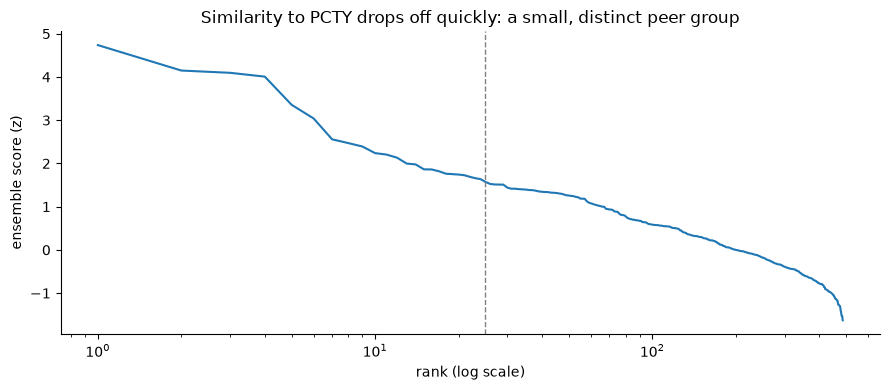

In [44]:
fig, ax = plt.subplots(figsize=(9, 4))
sc = S_t["ensemble"].drop(t_idx).sort_values(ascending=False).reset_index(drop=True)
ax.plot(sc.index + 1, sc.values, lw=1.5)
ax.axvline(TOP_K, ls="--", lw=1, c="grey")
ax.set(xscale="log", xlabel="rank (log scale)", ylabel="ensemble score (z)",
       title=f"Similarity to {TARGET} drops off quickly: a small, distinct peer group")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(OUT_DIR / f"score_curve_{TARGET}.png", dpi=150); plt.show()

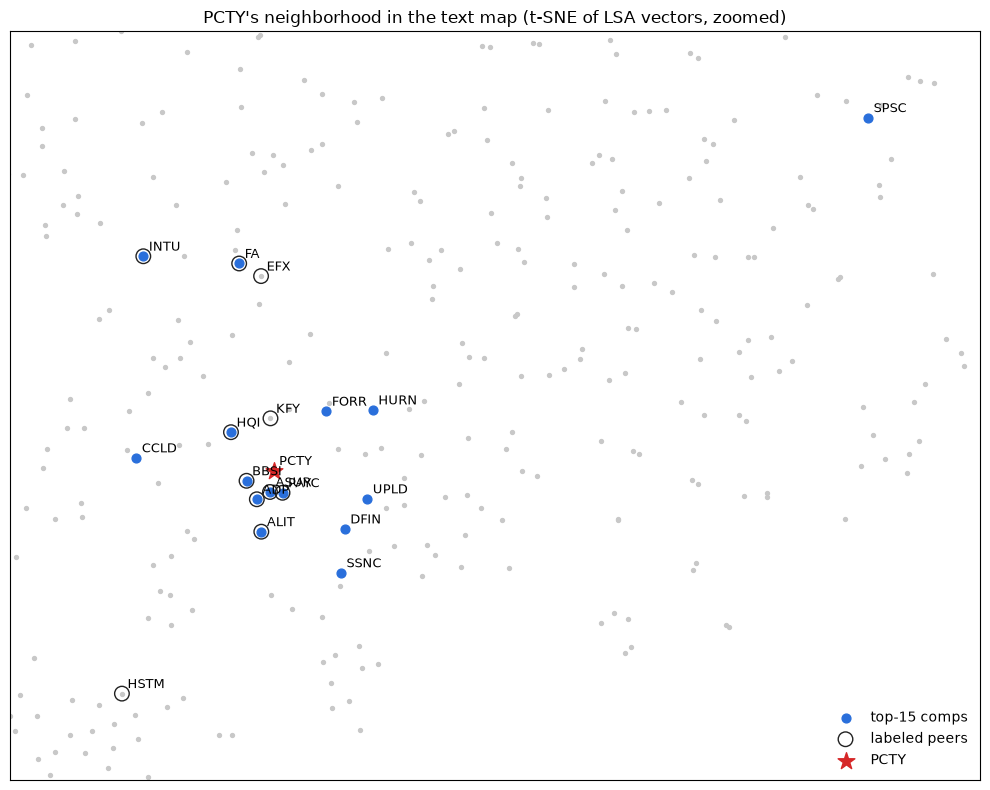

In [45]:
# 2-D map of the universe (t-SNE on the LSA vectors). Target in red, top comps in blue, labeled peers outlined.
xy = TSNE(n_components=2, metric="cosine", perplexity=30, init="pca", random_state=RNG).fit_transform(X_lsa)
top_idx = [int(U.index[U.target_ciq_ticker == x][0]) for x in comps.ticker[:15]]
peer_idx = [int(U.index[U.target_ciq_ticker == p][0]) for p in PEER_LABELS if p in set(U.target_ciq_ticker)]

fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(xy[:, 0], xy[:, 1], s=8, c="#c8c8c8")
ax.scatter(xy[top_idx, 0], xy[top_idx, 1], s=40, c="#2a6fdb", label="top-15 comps")
ax.scatter(xy[peer_idx, 0], xy[peer_idx, 1], s=110, facecolors="none", edgecolors="#222", lw=1, label="labeled peers")
ax.scatter(*xy[t_idx], s=160, c="#d62728", marker="*", label=TARGET)
for i in set(top_idx + peer_idx + [t_idx]):
    ax.annotate(U.target_ciq_ticker[i], xy[i], fontsize=9, xytext=(4, 4), textcoords="offset points")
# zoom to the target's neighborhood (the full map is mostly an undifferentiated cloud)
focus = np.array(top_idx + peer_idx + [t_idx])
(x0, y0), (x1, y1) = xy[focus].min(0), xy[focus].max(0)
pad_x, pad_y = 0.15 * (x1 - x0), 0.15 * (y1 - y0)
ax.set_xlim(x0 - pad_x, x1 + pad_x); ax.set_ylim(y0 - pad_y, y1 + pad_y)
ax.set(xticks=[], yticks=[], title=f"{TARGET}'s neighborhood in the text map (t-SNE of LSA vectors, zoomed)")
ax.legend(frameon=False, loc="best")
plt.tight_layout(); plt.savefig(OUT_DIR / f"map_{TARGET}.png", dpi=150); plt.show()

## 7. Re-use for any target
`find_comps` works for any matchable ticker:

In [46]:
find_comps("PCTY", k=10)[["rank", "ticker", "company", "sic4", "description", "score_ensemble", "why_similar (top shared terms)"]]

,rank,ticker,company,sic4,description,score_ensemble,why_similar (top shared terms)
0,1,BBSI,"Barrett Business Services, Inc.",7363,"Locally Supported Payroll, HR, Workers’ Comp & Benefits Discover PEO: Integrated payroll, HR, workers’ compensation, and risk services backed by local expertise and national resources. is a locally-supported, nationwide PEO committed to strengthening businesses through expert consulting, full-se...",4.737,"payroll, hr, hr payroll, workforce, consultants, brokers"
1,2,PAYC,"Paycom Software, Inc.",7370,The #1 HR and Payroll Software #1 HR and payroll software eliminates thousands of decisions through full-solution automation across the entire employee life cycle to help employees and leaders work smarter — all in a single database. is a cloud-based human capital management (HCM) software provi...,4.148,"payroll, hr, hr payroll, hr finance, hcm, employees"
2,3,ASUR,"Asure Software, Inc.",7370,"helps businesses develop Human Capital to get to the next level, stay compliant, and allocate their time, money and technology toward growth. leadership and dedication has enabled the company to help more than 100,000 growing businesses stay compliant, pay employees, and get the most from their ...",4.096,"payroll, hr, filing, tax, hcm, hr payroll"
3,4,ADP,"Automatic Data Processing, Inc.",7374,"Payroll, HR and Tax Services offers industry-leading online payroll and HR solutions, plus tax, compliance, benefit administration and more. — providing solutions that simplify work Since our very beginnings, we’ve been at the forefront of payroll and HR innovation. Today, as always, we're proud...",4.007,"payroll, hr, hr payroll, hcm, processes, tax"
4,5,HURN,Huron Consulting Group Inc.,8742,"Global Consulting for Healthcare, Education, Digital & More Businesses must be agile in their approach to understanding their customers — meeting today’s demands while also looking ahead to the future. is a global professional services firm that collaborates with organizations to help solve thei...",3.355,"payroll, hr, hr payroll, processes, clients, workforce"
5,6,FA,First Advantage Corporation,7389,"Global Background Checks & Screenings we are committed to providing you with industry-leading background checks and screening services supported by award-winning customer service. Trust in a Changing World™ At , it’s our mission to deliver innovative solutions and insights to help our customers ...",3.040,"workforce, hr, onboarding, workforce decisions, employees, tax"
6,7,INTU,Intuit Inc.,7372,: Outdo your financial goals—all in one place The platform puts a team of AI agents and trusted experts by your side. believes everyone should have the opportunity to prosper and we never stop working to find new innovative ways to make that possible. impact by the numbers Here’s what being a cu...,2.557,"automate, refund, taxes, spend, tax, insights automate"
7,8,SSNC,"SS&C Technologies Holdings, Inc.",7370,"- Investment Management Technology & Services Leading cloud-based provider of financial services technology solutions. owns and maintains the best financial technology in the industry For close to 40 years, has developed the technology and services to power our clients' success. With industry-sp...",2.470,"payroll, clients, platform, automation, ai-powered automation, unify"
8,9,DFIN,"Donnelley Financial Solutions, Inc.",7370,"Financial Risk, Compliance and Software Solutions We provide advanced financial solutions software, compliance tools, and global reporting support—empowering your business at every stage. is the leading provider of innovative, software and technology-enabled financial regulatory and compliance s...",2.391,"filing, finance, manual, clients, processes, reporting"
9,10,FORR,"Forrester Research, Inc.",8700,Helps Organizations Thrive Through Volatility is a leading global market research company that helps organizations exceed customer demands and excel with technology. helps business and technology leaders use customer

## 8. Notes and limitations
- **Data.** These are homepage, about and who-we-serve pages only, i.e. self-described marketing.
  Product breadth, customer segment and business model are often implied rather than stated.
- **Exclusions.** Companies with blocked or thin scrapes are excluded (see `excluded_companies.csv`).
  They are not ranked low; they simply cannot be scored yet.
- **Labels.** `PEER_LABELS` comes from one analyst's view and should be reviewed by the team. NDCG on
  roughly 11 labels for a single target is a sanity check, not a benchmark. Extend it by labeling peers for more targets.
- **Length bias.** Longer pages score somewhat higher against everyone (Spearman ≈ 0.5 with word count).
  The length-adjusted check in §5c shows the comps list and peer metrics barely move, but keep this in
  mind for companies with very short pages.
- **Leakage.** Names are masked, and investor-relations and earnings sentences are stripped. Some
  public-company language can still slip through (e.g. "Fortune 500").
- **Next steps.** (1) Have an LLM write a standardized profile per company (what they sell, who buys it,
  how they charge) and embed that profile instead of the marketing copy. (2) Use the comps' realized
  3-year revenue growth as a peer-based prior for the private target's growth forecast.